--- Primeras filas del DataFrame original ---


,valor
2024-01-01,52.827602
2024-01-02,50.133439
2024-01-03,54.543728
2024-01-04,59.400654
2024-01-05,51.094551



--- DataFrame Agregado Mensualmente ---


,valor
2024-01-31,56.415968
2024-02-29,69.711624
2024-03-31,79.420301
2024-04-30,83.554519
2024-05-31,82.081685


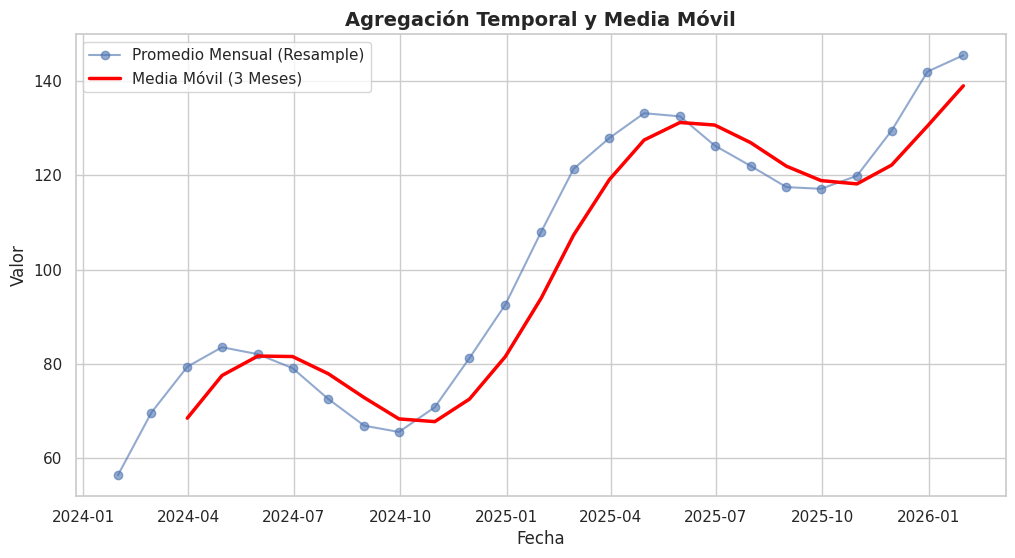

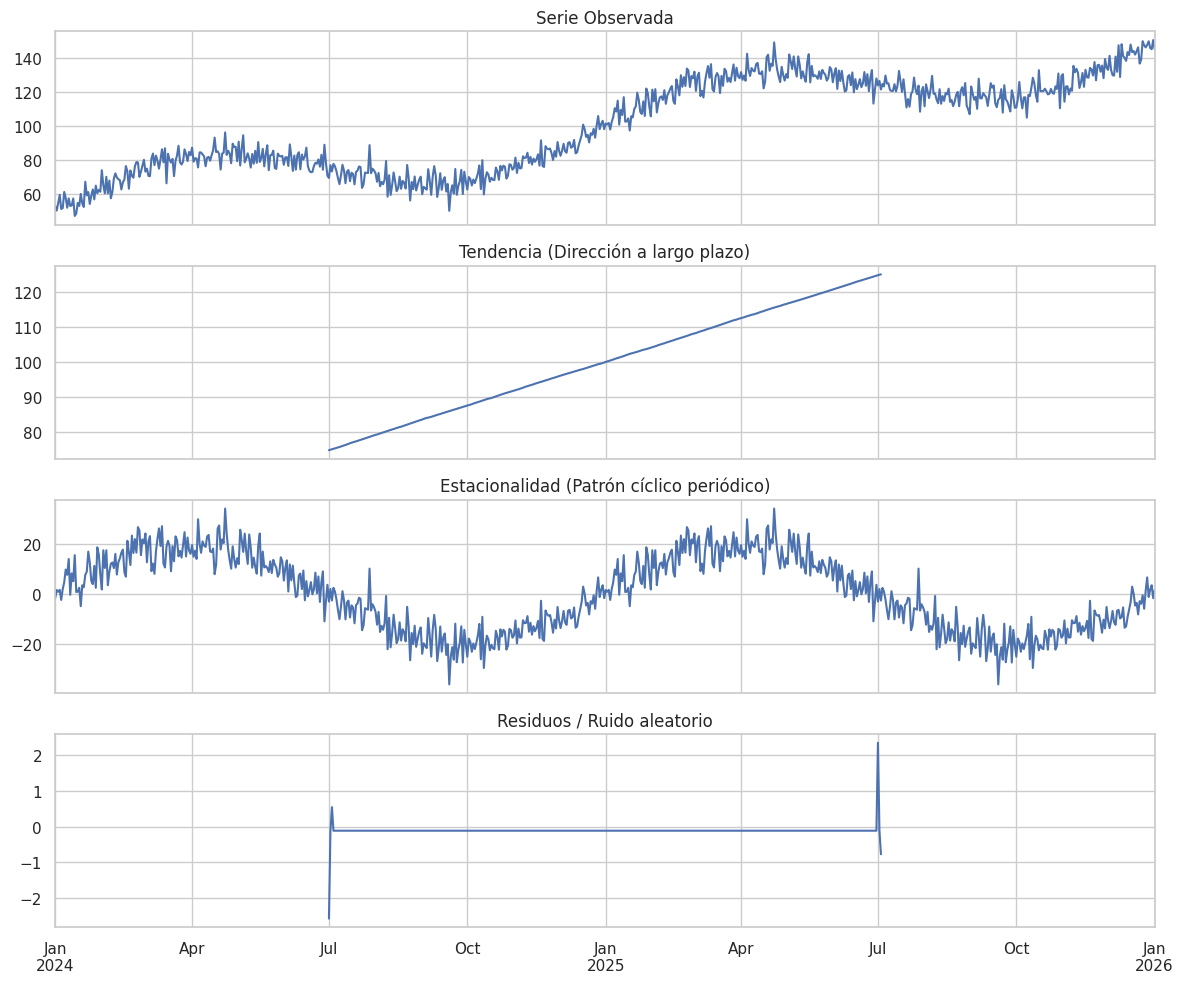

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# Configuración de estilo para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Crear un DataFrame de ejemplo con fecha e índice temporal diario
np.random.seed(42)
fechas = pd.date_range(start='2024-01-01', end='2026-01-01', freq='D')
# Simulamos una tendencia lineal ascendente + estacionalidad anual + ruido
tendencia = np.linspace(50, 150, len(fechas))
estacionalidad = 20 * np.sin(2 * np.pi * fechas.dayofyear / 365.25)
valores = tendencia + estacionalidad + np.random.normal(0, 5, len(fechas))

df = pd.DataFrame({'valor': valores}, index=fechas)
print("--- Primeras filas del DataFrame original ---")
display(df.head())

# 2. Agregación por periodo (Resample): Agrupar por mes calculando el promedio
df_mensual = df.resample('ME').mean() # 'ME' para fin de mes en pandas modernos
print("\n--- DataFrame Agregado Mensualmente ---")
display(df_mensual.head())

# 3. Cálculo de la Media Móvil (ventana de 3 meses)
df_mensual['media_movil_3m'] = df_mensual['valor'].rolling(window=3).mean()

# 4. Visualización de la Serie Original, Resampleada y Media Móvil
plt.figure(figsize=(12, 6))
plt.plot(df_mensual.index, df_mensual['valor'], label='Promedio Mensual (Resample)', marker='o', alpha=0.6)
plt.plot(df_mensual.index, df_mensual['media_movil_3m'], label='Media Móvil (3 Meses)', color='red', linewidth=2.5)
plt.title('Agregación Temporal y Media Móvil', fontsize=14, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Valor')
plt.legend()
plt.show()

# 5. Identificación de Tendencia y Estacionalidad mediante Descomposición Clásica
descomposicion = seasonal_decompose(df['valor'], model='additive', period=365)

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
descomposicion.observed.plot(ax=axes[0], title='Serie Observada')
descomposicion.trend.plot(ax=axes[1], title='Tendencia (Dirección a largo plazo)')
descomposicion.seasonal.plot(ax=axes[2], title='Estacionalidad (Patrón cíclico periódico)')
descomposicion.resid.plot(ax=axes[3], title='Residuos / Ruido aleatorio')
plt.tight_layout()
plt.show()

```markdown
# Problema 1 — Serie de Tiempo
Este bloque carga los datos con un índice temporal, aplica agregación mensual (resample), calcula una media móvil de 3 meses e identifica la tendencia y estacionalidad mediante descomposición.
```

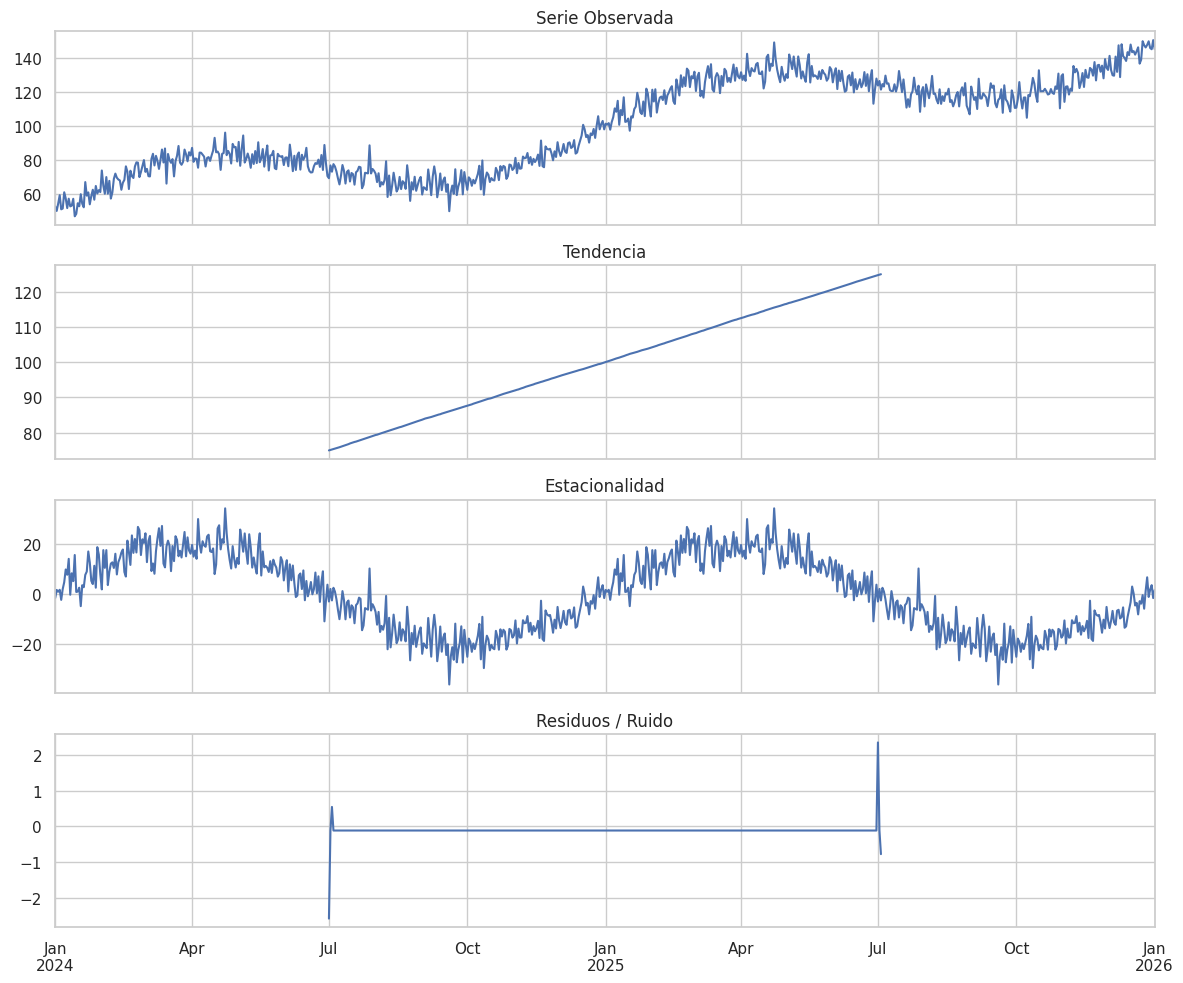

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="whitegrid")

# 1. Crear DataFrame con fecha como índice
np.random.seed(42)
fechas = pd.date_range(start='2024-01-01', end='2026-01-01', freq='D')
tendencia = np.linspace(50, 150, len(fechas))
estacionalidad = 20 * np.sin(2 * np.pi * fechas.dayofyear / 365.25)
valores = tendencia + estacionalidad + np.random.normal(0, 5, len(fechas))
df = pd.DataFrame({'valor': valores}, index=fechas)

# 2. Agregación por periodo (Resample)
df_mensual = df.resample('ME').mean()

# 3. Media Móvil
df_mensual['media_movil_3m'] = df_mensual['valor'].rolling(window=3).mean()

# 4. Identificar Tendencia y Estacionalidad (Descomposición)
descomposicion = seasonal_decompose(df['valor'], model='additive', period=365)

# Visualización
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
descomposicion.observed.plot(ax=axes[0], title='Serie Observada')
descomposicion.trend.plot(ax=axes[1], title='Tendencia')
descomposicion.seasonal.plot(ax=axes[2], title='Estacionalidad')
descomposicion.resid.plot(ax=axes[3], title='Residuos / Ruido')
plt.tight_layout()
plt.show()

```markdown
# Problema 2 — Visualización y Diseño
Este bloque demuestra de manera interactiva la selección correcta del tipo de gráfico según el objetivo (Evolución, Comparación y Proporción) y corrige errores de diseño comunes.
```

/tmp/ipykernel_5073/3287848330.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x=['Prod A', 'Prod B', 'Prod C'], y=[100, 120, 85], palette='Blues_d')


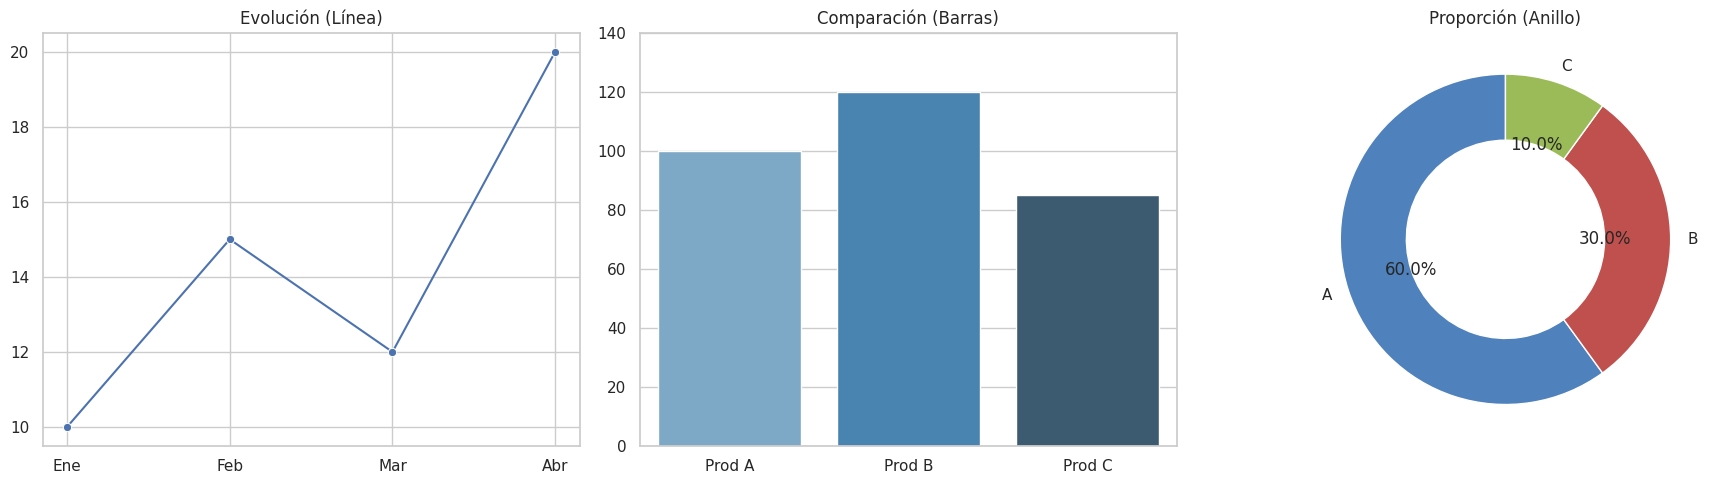

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Evolución (Líneas)
sns.lineplot(ax=axes[0], x=['Ene', 'Feb', 'Mar', 'Abr'], y=[10, 15, 12, 20], marker='o', color='b')
axes[0].set_title("Evolución (Línea)")

# 2. Comparación (Barras con Base en 0 para evitar ejes truncados)
sns.barplot(ax=axes[1], x=['Prod A', 'Prod B', 'Prod C'], y=[100, 120, 85], palette='Blues_d')
axes[1].set_ylim(0, 140) # Asegurando que inicie en 0
axes[1].set_title("Comparación (Barras)")

# 3. Proporción (Anillo limpio para pocas categorías, evitando tortas saturadas)
axes[2].pie([60, 30, 10], labels=['A', 'B', 'C'], autopct='%1.1f%%', startangle=90,
           colors=['#4F81BD', '#C0504D', '#9BBB59'], wedgeprops=dict(width=0.4, edgecolor='w'))
axes[2].set_title("Proporción (Anillo)")

plt.tight_layout()
plt.show()

```markdown
# Problema 3 — Optimización SQL, Métricas DAX y Traducción
Este bloque contiene la propuesta teórica detallada, la optimización de código SQL, las fórmulas DAX y la traducción técnica explicada al español.
```

In [5]:
# === OPTIMIZACIÓN SQL ===
query_lenta = """
SELECT *
FROM ventas
WHERE YEAR(fecha) = 2025 AND categoria LIKE '%electro%';
"""

query_optimizada = """
SELECT id_venta, fecha, total, id_categoria
FROM ventas
WHERE fecha >= '2025-01-01' AND fecha < '2026-01-01'
  AND id_categoria = 5;
"""

# === MEDIDAS DAX ===
dax_total_ventas = "Total Ventas = SUM(Ventas[Monto])"
dax_porcentaje_total = """
Pct del Total =
DIVIDE(
    [Total Ventas],
    CALCULATE([Total Ventas], ALL(Ventas))
)
"""

# === TRADUCCIÓN TÉCNICA ===
traduccion_indices = """
An index speeds up a database query because it creates a sorted B-Tree structure of column values...
-> Un índice acelera las consultas de base de datos porque genera una estructura ordenada de tipo árbol-B
   con los valores de las columnas, permitiendo al motor de base de datos encontrar filas específicas de manera inmediata
   sin necesidad de realizar una costosa búsqueda completa en toda la tabla.
"""

traduccion_dax = """
In Power BI, a measure is a dynamic calculation evaluated on-the-fly...
-> En Power BI, una medida es un cálculo dinámico evaluado en tiempo real en función del contexto de filtro activo
   en los elementos visuales del reporte; esto significa que realiza los cálculos dinámicamente sin requerir almacenamiento
   físico por cada fila en el modelo de datos.
"""

print("✔ Estructuras de consulta y fórmulas DAX cargadas de forma independiente para documentación.")

✔ Estructuras de consulta y fórmulas DAX cargadas de forma independiente para documentación.


```markdown
## Problem 3 — Database Indexes and Power BI Measures

An index speeds up a database query because it creates a sorted B-Tree structure of column values, allowing the database engine to locate and retrieve specific rows instantly without performing a costly full table scan. In Power BI, a measure is a dynamic calculation evaluated on-the-fly based on the active filter context of your report visuals, meaning it computes results dynamically without consuming physical storage space for every row in the data model.
```